In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt

print(tf.__version__)
print(os.getcwd())

2.17.1
/kaggle/working
True


In [3]:
# dataset_path = "/kaggle/input/lung-cancer-dataset-clahe/data_v3"
dataset_path = "/kaggle/input/lung-cancer-dataset-3/data_v2"
input_shape = (250, 250)

In [60]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "train"),
    image_size=input_shape,  # Resize images
    batch_size=32,
    shuffle=True,
    # label_mode="categorical",
    label_mode="binary",
    color_mode="grayscale"  # only if loading grayscale images
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "val"),
    image_size=input_shape,  # Resize images
    batch_size=32,
    shuffle=True,
    # label_mode="categorical",
    label_mode="binary",
    color_mode="grayscale"   # only if loading grayscale images
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "test"),
    image_size=input_shape,  # Resize images
    batch_size=32,
    shuffle=True,
    # label_mode="categorical",
    label_mode="binary",
    color_mode="grayscale"   # only if loading grayscale images
)

train_dataset.class_names

Found 3380 files belonging to 2 classes.
Found 896 files belonging to 2 classes.
Found 1128 files belonging to 2 classes.


['benign', 'malignant']

In [61]:
def show_image(batch):
    image_batch, label_batch = next(iter(batch))

    # Convert tensor to NumPy for visualization
    image_batch = image_batch.numpy()
    
    # Display the first few images (e.g., first 5)
    plt.figure(figsize=(10, 5))
    for i in range(5):  # Show only first 5 images
        plt.subplot(1, 5, i + 1)
        plt.imshow(image_batch[i].squeeze(), cmap="gray")  # Use squeeze() for grayscale images
        plt.axis("off")
    plt.show()

In [62]:
data_augmentation_layer = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),  # Randomly flip images
    tf.keras.layers.RandomRotation(0.7),                   # Randomly rotate images
])

# rescale_layer = tf.keras.layers.Rescaling(1./255)  # Rescale to [0, 1]
rescale_layer = tf.keras.layers.Rescaling(1./127.5, offset=-1)  # Rescale to [-1, 1]

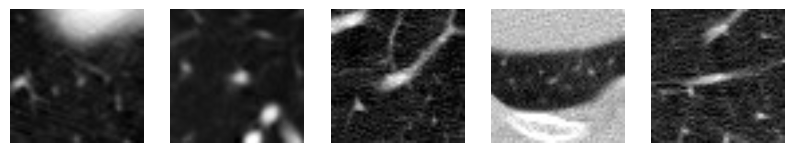

In [8]:
show_image(test_dataset)

In [63]:
# Apply data augmentation and preprocessing to the datasets

train_dataset = train_dataset.map(lambda x, y: (data_augmentation_layer(x), y))
train_dataset = train_dataset.map(
    lambda x, y: (rescale_layer(x), y)
)

val_dataset = val_dataset.map(lambda x, y: (data_augmentation_layer(x), y))
val_dataset = val_dataset.map(
    lambda x, y: (rescale_layer(x), y)
)

test_dataset = test_dataset.map(lambda x, y: (data_augmentation_layer(x), y))
test_dataset = test_dataset.map(
    lambda x, y: (rescale_layer(x), y)
)

In [ ]:
from tensorflow.keras.layers import Layer, Dense, Conv2D, GlobalAveragePooling2D, GlobalMaxPooling2D, Reshape, Add, Activation, Multiply, Concatenate

class CBAMLayer(Layer):
    def __init__(self, ratio=8, kernel_size=7, **kwargs):
        super(CBAMLayer, self).__init__(**kwargs)
        self.ratio = ratio
        self.kernel_size = kernel_size

    def build(self, input_shape):
        self.channel = input_shape[-1]  # Get the number of channels from input shape
        
        # Define shared MLP layers for channel attention
        self.shared_dense_one = Dense(self.channel // self.ratio, activation="relu", use_bias=True, kernel_initializer="he_normal")
        self.shared_dense_two = Dense(self.channel, use_bias=True, kernel_initializer="he_normal")

        # Define the spatial attention convolutional layer
        self.spatial_conv = Conv2D(filters=1, kernel_size=self.kernel_size, strides=1, padding="same", activation="sigmoid", use_bias=False, kernel_initializer="he_normal")

        super(CBAMLayer, self).build(input_shape)  # Important to call this

    def call(self, inputs, **kwargs):
        # === Channel Attention ===
        avg_pool = GlobalAveragePooling2D()(inputs)
        max_pool = GlobalMaxPooling2D()(inputs)
        
        avg_pool = Reshape((1, 1, self.channel))(avg_pool)
        max_pool = Reshape((1, 1, self.channel))(max_pool)
        
        avg_fc = self.shared_dense_two(self.shared_dense_one(avg_pool))
        max_fc = self.shared_dense_two(self.shared_dense_one(max_pool))

        channel_attention = Activation('sigmoid')(Add()([avg_fc, max_fc]))
        channel_refined = Multiply()([inputs, channel_attention])

        # === Spatial Attention ===
        avg_spatial = tf.reduce_mean(channel_refined, axis=-1, keepdims=True)
        max_spatial = tf.reduce_max(channel_refined, axis=-1, keepdims=True)

        concat = Concatenate(axis=-1)([avg_spatial, max_spatial])
        spatial_attention = self.spatial_conv(concat)
        
        output = Multiply()([channel_refined, spatial_attention])
        return output

    def get_config(self):
        config = super(CBAMLayer, self).get_config()
        config.update({"ratio": self.ratio, "kernel_size": self.kernel_size})
        return config

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input, BatchNormalization, GlobalAveragePooling2D, ReLU
from tensorflow.keras.activations import gelu
from tensorflow.keras.regularizers import l2

model = Sequential([
    Input(shape=(*input_shape, 1)),

    # Block 1
    Conv2D(64, (3, 3), activation='relu', padding="same"),
    Conv2D(64, (3, 3), activation='relu', padding="same"),
    CBAMLayer(ratio=2, kernel_size=3),
    MaxPooling2D((2, 2)),
    
    Conv2D(64, (3, 3), padding="same", kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    ReLU(),
    CBAMLayer(ratio=2, kernel_size=3),
    MaxPooling2D((2, 2)),

    
    # Block 2
    Conv2D(128, (3, 3), activation='relu', padding="same"),
    Conv2D(128, (3, 3), activation='relu', padding="same"),
    CBAMLayer(ratio=4, kernel_size=5),
    MaxPooling2D((2, 2)),
    
    Conv2D(128, (3, 3), padding="same", kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    ReLU(),
    CBAMLayer(ratio=4, kernel_size=5),
    MaxPooling2D((2, 2)),

    
    # Block 3
    Conv2D(256, (3, 3), activation='relu', padding="same"),
    Conv2D(256, (3, 3), activation='relu', padding="same"),
    CBAMLayer(ratio=8, kernel_size=7),
    MaxPooling2D((2, 2)),
    
    Conv2D(256, (3, 3), padding="same", kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    ReLU(),
    CBAMLayer(ratio=8, kernel_size=7),


    Flatten(),
    # GlobalAveragePooling2D(),
    Dense(1024, activation='relu'),
    Dropout(0.4),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(256, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_120 (Conv2D)                  │ (None, 250, 250, 64)        │             640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_121 (Conv2D)                  │ (None, 250, 250, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ cbam_layer_48 (CBAMLayer)            │ (None, 250, 250, 64)        │           4,210 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_40 (MaxPooling2D)      │ (None, 125, 125, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_122 (Conv2D)                  │ (None, 125, 125, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_24               │ (None, 125, 125, 64)        │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu_24 (ReLU)                      │ (None, 125, 125, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ cbam_layer_49 (CBAMLayer)            │ (None, 125, 125, 64)        │           4,210 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_41 (MaxPooling2D)      │ (None, 62, 62, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_123 (Conv2D)                  │ (None, 62, 62, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_124 (Conv2D)                  │ (None, 62, 62, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ cbam_layer_50 (CBAMLayer)            │ (None, 62, 62, 128)         │           8,402 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_42 (MaxPooling2D)      │ (None, 31, 31, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_125 (Conv2D)                  │ (None, 31, 31, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_25               │ (None, 31, 31, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu_25 (ReLU)                      │ (None, 31, 31, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ cbam_layer_51 (CBAMLayer)            │ (None, 31, 31, 128)         │           8,402 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_43 (MaxPooling2D)      │ (None, 15, 15, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_126 (Conv2D)                  │ (None, 15, 15, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_127 (Conv2D)                  │ (None, 15, 15, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 15,153,933 (57.81 MB)

 Trainable params: 15,153,037 (57.80 MB)

 Non-trainable params: 896 (3.50 KB)

In [72]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.metrics import categorical_accuracy, binary_accuracy

# optimizer = optimizer = Adam(
#     learning_rate=0.0001,
#     beta_1=0.9,
#     beta_2=0.999,
#     epsilon=1e-07,
#     weight_decay=1e-5  # Adding weight decay for better regularization
# )


optimizer = AdamW(
   learning_rate=0.0001,
   beta_1=0.9,
   beta_2=0.999,
   epsilon=1e-07,
   weight_decay=1e-5
)

model.compile(
    optimizer=optimizer, 
    # loss='categorical_crossentropy', 
    loss='binary_crossentropy', 
    metrics=[
        # categorical_accuracy,
        # binary_accuracy,
        'accuracy',
        tf.keras.metrics.AUC(name='auc'),  # ROC AUC
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.F1Score(name='f1')
    ])

In [73]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
model_checkpoint = ModelCheckpoint("best_model_14.keras", save_best_only=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=1e-6)

history = model.fit(train_dataset, epochs=30, validation_data=val_dataset, callbacks=[reduce_lr, early_stopping, model_checkpoint])

Epoch 1/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 50s 293ms/step - accuracy: 0.6488 - auc: 0.7089 - f1: 0.6668 - loss: 1.0308 - precision: 0.6458 - recall: 0.6482 - val_accuracy: 0.5000 - val_auc: 0.5000 - val_f1: 0.6667 - val_loss: 1.0595 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 2/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 19s 181ms/step - accuracy: 0.8223 - auc: 0.8890 - f1: 0.6688 - loss: 0.7786 - precision: 0.8304 - recall: 0.8121 - val_accuracy: 0.5000 - val_auc: 0.5000 - val_f1: 0.6667 - val_loss: 1.0470 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 3/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 18s 172ms/step - accuracy: 0.8564 - auc: 0.9306 - f1: 0.6612 - loss: 0.6637 - precision: 0.8535 - recall: 0.8554 - val_accuracy: 0.5000 - val_auc: 0.6434 - val_f1: 0.6667 - val_loss: 1.0981 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 4/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 18s 171ms/step - accuracy: 

In [59]:
model.save('/kaggle/working/trained_lung_cancer_model_14.keras')

In [74]:
result = model.evaluate(test_dataset)

36/36 ━━━━━━━━━━━━━━━━━━━━ 6s 165ms/step - accuracy: 0.9293 - auc: 0.9826 - f1: 0.6944 - loss: 0.3834 - precision: 0.9554 - recall: 0.9097


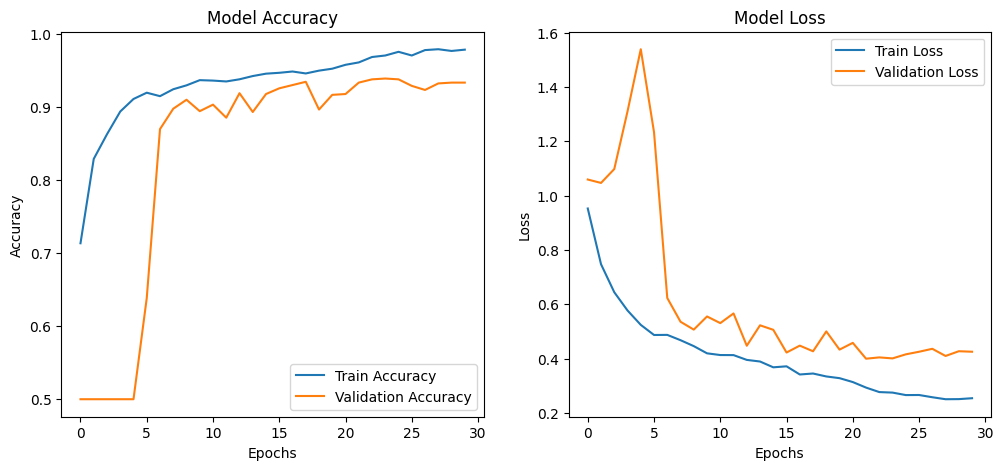

In [75]:

# Plot training & validation accuracy and loss
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Model Accuracy')

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Model Loss')

plt.show()

In [76]:

# Convert dataset to NumPy arrays
def get_labels_and_predictions(dataset, model):
    y_true, y_pred_prob = [], []

    for images, labels in dataset:
        y_true.extend(labels.numpy())  # Convert tensor to NumPy
        y_pred_prob.extend(model.predict(images))  # Get predicted probabilities

    y_true = np.array(y_true)
    y_pred_prob = np.array(y_pred_prob).flatten()  # Flatten if needed
    y_pred = (y_pred_prob > 0.5).astype(int)  # Convert probabilities to binary labels

    return y_true, y_pred, y_pred_prob

y_true, y_pred, y_pred_prob = get_labels_and_predictions(test_dataset, model)


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━

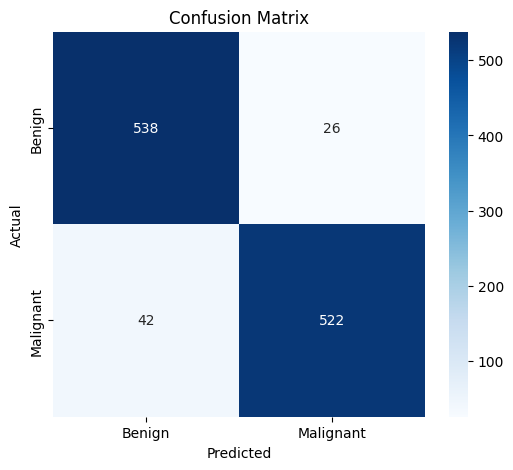

In [77]:
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Get predictions
# y_pred = (model.predict(X_test) > 0.5).astype("int32")  # Convert probabilities to 0/1
cm = confusion_matrix(y_true, y_pred)

# Plot confusion matrix
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [78]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, target_names=['Benign', 'Malignant']))


              precision    recall  f1-score   support

      Benign       0.93      0.95      0.94       564
   Malignant       0.95      0.93      0.94       564

    accuracy                           0.94      1128
   macro avg       0.94      0.94      0.94      1128
weighted avg       0.94      0.94      0.94      1128



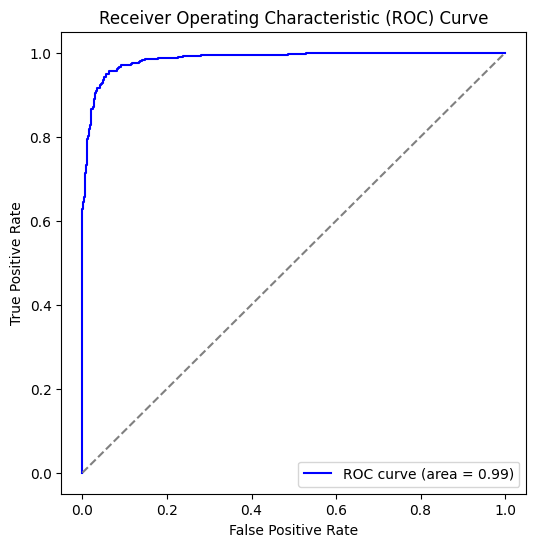

In [79]:
from sklearn.metrics import roc_curve, auc

# Get predicted probabilities
# y_prob = model.predict(X_test).ravel()  # Flatten array

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y_true, y_pred_prob)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal reference line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.show()


In [80]:
from sklearn.metrics import roc_auc_score

auc_score = roc_auc_score(y_true, y_pred_prob)
print(f"AUC Score: {auc_score:.2f}")


AUC Score: 0.99
